<a href="https://colab.research.google.com/github/192524103simats-star/CSA4705/blob/main/UNIT_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import tensorflow as tf

# Sample source and target sequences
X=np.array([[1,2,3],[2,3,0],[3,1,2],[1,3,2]])
Y=np.array([[2,3,1],[3,1,0],[1,2,3],[2,1,3]])

decoder=Y[:,:-1]
target=Y[:,1:]

encoder_input=tf.keras.Input(shape=(3,))
decoder_input=tf.keras.Input(shape=(2,))

enc=tf.keras.layers.Embedding(4,16)(encoder_input)
_,h,c=tf.keras.layers.LSTM(32,return_state=True)(enc)

dec=tf.keras.layers.Embedding(4,16)(decoder_input)
out=tf.keras.layers.LSTM(32,return_sequences=True)(
    dec,initial_state=[h,c])
out=tf.keras.layers.Dense(4,activation='softmax')(out)

model=tf.keras.Model([encoder_input,decoder_input],out)
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy')
model.fit([X,decoder],target,epochs=100,verbose=0)

print("Translation model trained successfully")
print("Output shape:",model.output_shape)


Translation model trained successfully
Output shape: (None, 2, 4)


In [2]:

import numpy as np
import tensorflow as tf

data=np.sin(np.arange(400)*0.05)
X=np.array([data[i:i+30] for i in range(370)])
y=data[30:]
X=X.reshape(-1,30,1)

for layer in [tf.keras.layers.SimpleRNN(32),
              tf.keras.layers.LSTM(32)]:
    model=tf.keras.Sequential([
        tf.keras.layers.Input(shape=(30,1)),
        layer,
        tf.keras.layers.Dense(1)
    ])
    model.compile(optimizer='adam',loss='mse')
    model.fit(X[:300],y[:300],epochs=5,verbose=0)
    loss=model.evaluate(X[300:],y[300:],verbose=0)
    print(type(layer).__name__,"Loss:",loss)


SimpleRNN Loss: 0.0009172940626740456
LSTM Loss: 0.030688384547829628


In [3]:

import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X=np.random.RandomState(42).rand(100,6)

X=StandardScaler().fit_transform(X)

pca=PCA(n_components=2)
reduced=pca.fit_transform(X)

print("Original Shape:",X.shape)
print("Reduced Shape:",reduced.shape)
print("Explained Variance:",pca.explained_variance_ratio_)
print("Transformed Data:")
print(reduced[:5])


Original Shape: (100, 6)
Reduced Shape: (100, 2)
Explained Variance: [0.21085376 0.18818037]
Transformed Data:
[[-1.1704265  -0.87832483]
 [-0.00924367  0.4941458 ]
 [-0.66606534  0.94896383]
 [-0.60854125 -0.51287627]
 [-0.30381603 -1.05687087]]


In [4]:

from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

iris=load_iris()
X=StandardScaler().fit_transform(iris.data)
y=iris.target

X=PCA(n_components=2).fit_transform(X)

Xtr,Xte,ytr,yte=train_test_split(
    X,y,test_size=0.2,random_state=42,stratify=y)

model=KNeighborsClassifier(n_neighbors=5)
model.fit(Xtr,ytr)

pred=model.predict(Xte)
print("Accuracy:",accuracy_score(yte,pred))
print("Reduced Features:",X.shape[1])


Accuracy: 0.9
Reduced Features: 2


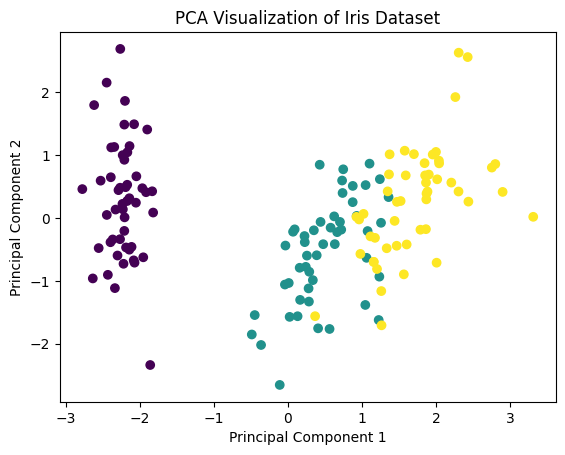

Explained Variance: [0.72962445 0.22850762]


In [5]:

import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

iris=load_iris()
X=StandardScaler().fit_transform(iris.data)

pca=PCA(n_components=2)
X_pca=pca.fit_transform(X)

plt.scatter(X_pca[:,0],X_pca[:,1],c=iris.target)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Iris Dataset")
plt.show()

print("Explained Variance:",pca.explained_variance_ratio_)


In [6]:

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.pipeline import make_pipeline

data=load_breast_cancer()
Xtr,Xte,ytr,yte=train_test_split(
    data.data,data.target,test_size=0.2,
    random_state=42,stratify=data.target)

models={
    "Before PCA":make_pipeline(
        StandardScaler(),LogisticRegression(max_iter=2000)),
    "After PCA":make_pipeline(
        StandardScaler(),PCA(n_components=10),
        LogisticRegression(max_iter=2000))
}

for name,model in models.items():
    model.fit(Xtr,ytr)
    pred=model.predict(Xte)
    print(name,accuracy_score(yte,pred))


Before PCA 0.9824561403508771
After PCA 0.9736842105263158


In [7]:

import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

X=np.random.RandomState(42).rand(200,10)
X=StandardScaler().fit_transform(X)

pca=PCA()
pca.fit(X)

variance=np.cumsum(pca.explained_variance_ratio_)
n=np.argmax(variance>=0.95)+1

print("Explained Variance:",variance)
print("Components Required:",n)
print("Total Variance:",variance[n-1])


Explained Variance: [0.13555297 0.26011807 0.37647246 0.48103474 0.57955277 0.67583598
 0.76739929 0.85545519 0.93125467 1.        ]
Components Required: 10
Total Variance: 1.0


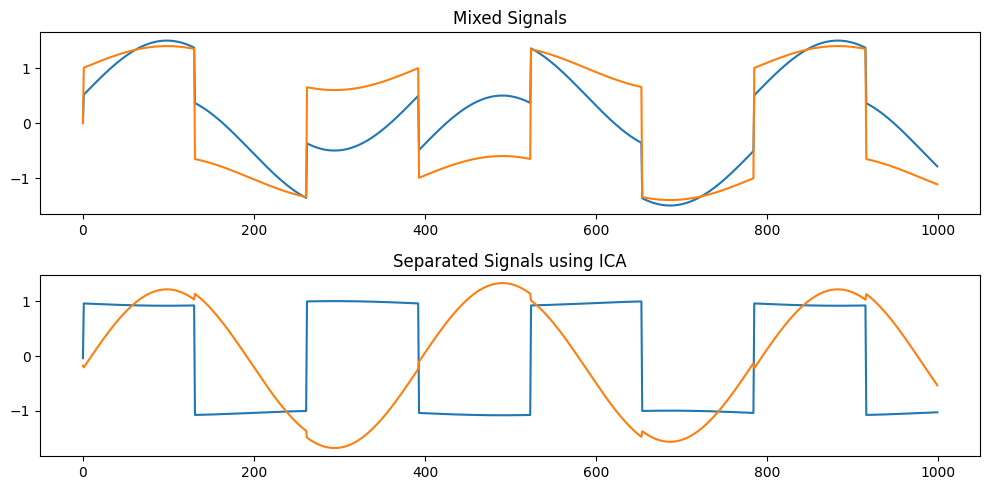

ICA Separation Completed


In [8]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import FastICA

t=np.linspace(0,8,1000)
s1=np.sin(2*t)
s2=np.sign(np.sin(3*t))
S=np.c_[s1,s2]

A=np.array([[1,0.5],[0.4,1]])
X=S@A.T

ica=FastICA(n_components=2,random_state=42,
            whiten='unit-variance')
separated=ica.fit_transform(X)

plt.figure(figsize=(10,5))
plt.subplot(2,1,1)
plt.plot(X)
plt.title("Mixed Signals")
plt.subplot(2,1,2)
plt.plot(separated)
plt.title("Separated Signals using ICA")
plt.tight_layout()
plt.show()

print("ICA Separation Completed")


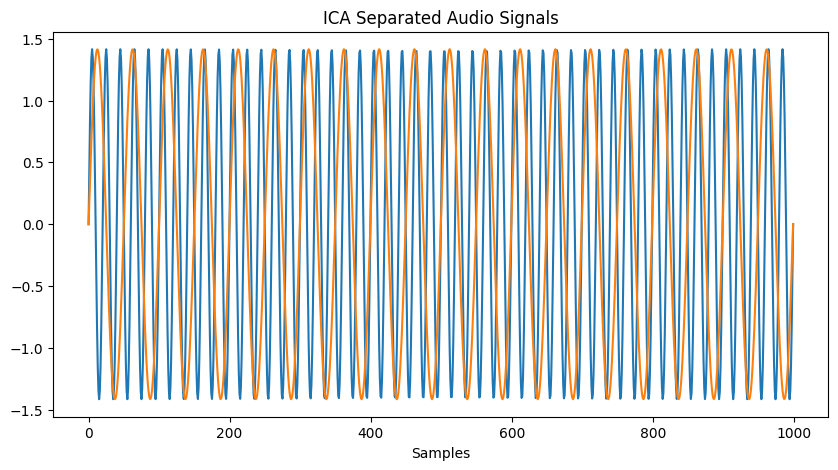

Separated Signals Shape: (1000, 2)


In [9]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import FastICA

t=np.linspace(0,10,1000)
s1=np.sin(2*np.pi*2*t)
s2=np.sin(2*np.pi*5*t)

S=np.c_[s1,s2]
A=np.array([[1,0.6],[0.5,1]])
X=S@A.T

ica=FastICA(n_components=2,random_state=42,
            whiten='unit-variance')
result=ica.fit_transform(X)

plt.figure(figsize=(10,5))
plt.plot(result)
plt.title("ICA Separated Audio Signals")
plt.xlabel("Samples")
plt.show()

print("Separated Signals Shape:",result.shape)


In [10]:

import numpy as np
from sklearn.decomposition import PCA, FastICA
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
S=np.random.laplace(size=(500,2))
A=np.array([[1,0.5],[0.4,1]])
X=S@A.T

X=StandardScaler().fit_transform(X)

pca=PCA(n_components=2)
ica=FastICA(n_components=2,random_state=42,
            whiten='unit-variance')

P=pca.fit_transform(X)
I=ica.fit_transform(X)

print("PCA Shape:",P.shape)
print("ICA Shape:",I.shape)
print("PCA Variance:",pca.explained_variance_ratio_)
print("ICA Components:")
print(ica.components_)


PCA Shape: (500, 2)
ICA Shape: (500, 2)
PCA Variance: [0.87832794 0.12167206]
ICA Components:
[[ 0.65154484 -1.39772372]
 [-1.38377187  0.62105044]]


In [11]:

import numpy as np
from sklearn.decomposition import FactorAnalysis
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
X=np.random.rand(100,5)

X=StandardScaler().fit_transform(X)

fa=FactorAnalysis(n_components=2,random_state=42)
transformed=fa.fit_transform(X)

print("Original Shape:",X.shape)
print("Factor Shape:",transformed.shape)
print("Factor Loadings:")
print(fa.components_)


Original Shape: (100, 5)
Factor Shape: (100, 2)
Factor Loadings:
[[ 0.28328522 -0.28906624 -0.33045247  0.39352046  0.49565613]
 [-0.48737835  0.11952329  0.28500588  0.07857417  0.39215123]]


In [12]:

import numpy as np
from sklearn.decomposition import FactorAnalysis
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
X=np.random.rand(200,6)

X=StandardScaler().fit_transform(X)

fa=FactorAnalysis(n_components=3,random_state=42)
features=fa.fit_transform(X)

print("Customer Data Shape:",X.shape)
print("Extracted Factors:",features.shape)
print("Factor Loadings:")
print(fa.components_)


Customer Data Shape: (200, 6)
Extracted Factors: (200, 3)
Factor Loadings:
[[ 0.15470191 -0.29081096 -0.00043379  0.29983126  0.29061562  0.14386332]
 [-0.3024678   0.01908714  0.01056451  0.15039138  0.10258736 -0.16725658]
 [ 0.0697288   0.03263699  0.32702094  0.09477861 -0.07414479 -0.06540895]]


In [13]:

import numpy as np
from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

X=np.random.RandomState(42).rand(200,5)
X=StandardScaler().fit_transform(X)

pca=PCA(n_components=2)
P=pca.fit_transform(X)
X1=pca.inverse_transform(P)

fa=FactorAnalysis(n_components=2,random_state=42)
F=fa.fit_transform(X)
X2=F@fa.components_+fa.mean_

print("PCA Error:",mean_squared_error(X,X1))
print("Factor Analysis Error:",mean_squared_error(X,X2))


PCA Error: 0.5287684760888198
Factor Analysis Error: 0.7876725402841428


Estimated Mean:
[ 5.09323391 10.02570897]
Estimated Covariance:
[[2.01502911 0.39976672]
 [0.39976672 2.79745683]]


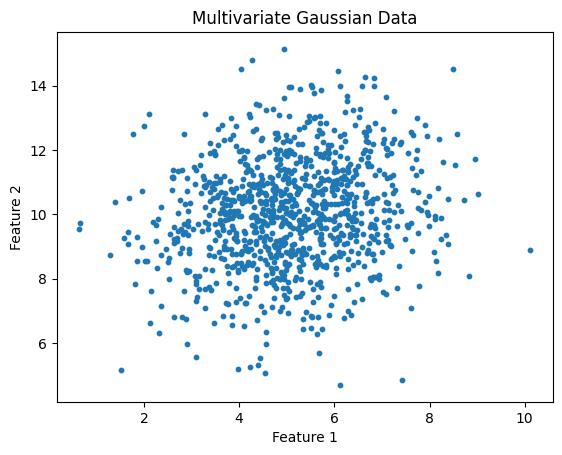

In [14]:

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

mean=[5,10]
cov=[[2,0.5],[0.5,3]]

data=np.random.multivariate_normal(mean,cov,1000)

print("Estimated Mean:")
print(np.mean(data,axis=0))

print("Estimated Covariance:")
print(np.cov(data.T))

plt.scatter(data[:,0],data[:,1],s=10)
plt.title("Multivariate Gaussian Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


Cluster Labels:
[1 1 1 1 1 1 1 1 1 1]
Membership Probabilities:
[[7.39958918e-32 1.00000000e+00 1.06560500e-24]
 [3.56168403e-24 1.00000000e+00 5.34861656e-17]
 [5.27796015e-35 1.00000000e+00 6.40756830e-25]
 [8.80471512e-24 1.00000000e+00 1.30136235e-20]
 [1.82895643e-32 1.00000000e+00 3.25115531e-21]]


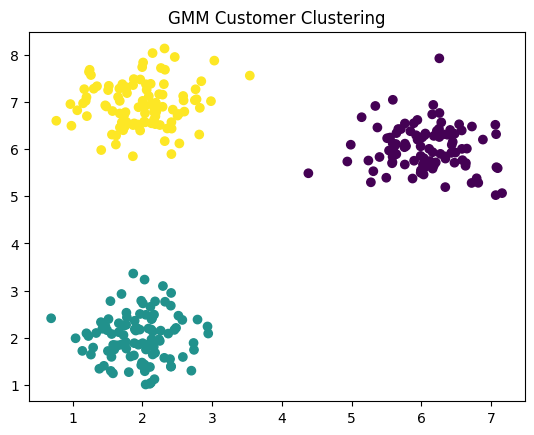

In [15]:

import numpy as np
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt

np.random.seed(42)
X=np.vstack([
    np.random.normal([2,2],0.5,(100,2)),
    np.random.normal([6,6],0.5,(100,2)),
    np.random.normal([2,7],0.5,(100,2))
])

gmm=GaussianMixture(n_components=3,random_state=42)
gmm.fit(X)

labels=gmm.predict(X)
prob=gmm.predict_proba(X)

print("Cluster Labels:")
print(labels[:10])

print("Membership Probabilities:")
print(prob[:5])

plt.scatter(X[:,0],X[:,1],c=labels)
plt.title("GMM Customer Clustering")
plt.show()


In [16]:

import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

np.random.seed(42)

X=np.random.rand(500,8)
y=(X[:,0]+X[:,1]+X[:,2]>1.5).astype(int)

Xtr,Xte,ytr,yte=train_test_split(
    X,y,test_size=0.2,random_state=42,stratify=y)

model=tf.keras.Sequential([
    tf.keras.layers.Dense(32,activation='relu',input_shape=(8,)),
    tf.keras.layers.Dense(16,activation='relu'),
    tf.keras.layers.Dense(1,activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.fit(Xtr,ytr,epochs=10,verbose=0)

pred=(model.predict(Xte,verbose=0)>0.5).astype(int)

print("Test Accuracy:",accuracy_score(yte,pred))
print("Healthcare Prediction:",pred[:5].flatten())


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Test Accuracy: 0.81
Healthcare Prediction: [1 0 1 0 0]
